# Proinsulin fed-batch — 5 L bioreactor mechanistic model, simulator, optimiser

9 ODE states: V, Xv, Xd, S, A, P_sol, P_ib, DO, T. Adds (vs the original 6-state version) dissolved oxygen + kLa mass transfer, energy balance with proportional jacket cooling, soluble-vs-inclusion-body partitioning of proinsulin, Hill-driven dynamic metabolic burden, IPTG toxicity, and OUR-coupled metabolic heat. Operating envelope is a 5 L lab fermenter at 2.5 L initial working volume. See `docs/MODEL.md` §2–§3 for derivations and `docs/logs.md` for run history.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import differential_evolution
P = dict(mu_max=0.6, Ks=0.05, Ki_S=80.0, Kdo=0.2, Ki_A=8.0, kd0=0.02, k_tox_A=0.005, k_tox_IPTG=0.1, Yxs=0.45, ms=0.03, Yps=0.15, Yxo=1.1, mo=0.4, Ypo=0.5, alpha=0.12, beta=0.0, K_IPTG=0.05, n_Hill=2, T_opt_g=37.0, sigma_g=5.0, T_opt_p=29.0, sigma_p=4.0, qs_crit=0.4, Y_AS=0.4, k_au=0.1, K_au=0.5, T_IB_50=32.0, sigma_IB=2.0, mu_crit_IB=0.3, phi_min=0.4, kLa_c=0.027, kLa_aN=1.5, kLa_bF=0.5, DO_star=7.5, rho=1.0, Cp=4.18, K_jacket=200.0, Q_ag=10.0, H_O2=0.46, T_feed=25.0, V0=2.5, Xv0=0.1, S0=10.0, DO0=7.5, T0=37.0)


In [2]:
def smooth_step(x, c, w):
    return 1.0 / (1.0 + np.exp(-(x - c) / w))

def derivs(t, y, T_set_prod, IPTG_dose, X_ind, F_s, S_f, N_rpm, F_air_vvm):
    V, Xv, Xd, S, A, P_sol, P_ib, DO, T = y
    S_c = max(S, 0.0)
    A_c = max(A, 0.0)
    DO_c = max(DO, 0.0)
    ind = smooth_step(Xv, X_ind, 0.5)
    IPTG = IPTG_dose * ind
    T_set = P['T_opt_g'] + (T_set_prod - P['T_opt_g']) * ind
    iptg_n = IPTG ** P['n_Hill']
    hill = iptg_n / (P['K_IPTG'] ** P['n_Hill'] + iptg_n) if IPTG > 0 else 0.0
    phi = 1.0 - (1.0 - P['phi_min']) * ind * hill
    fT_g = np.exp(-0.5 * ((T - P['T_opt_g']) / P['sigma_g']) ** 2)
    fT_p = np.exp(-0.5 * ((T - P['T_opt_p']) / P['sigma_p']) ** 2)
    haldane = S_c / (P['Ks'] + S_c + S_c ** 2 / P['Ki_S'])
    do_term = DO_c / (P['Kdo'] + DO_c)
    ace_inh = P['Ki_A'] / (P['Ki_A'] + A_c)
    mu = P['mu_max'] * fT_g * haldane * do_term * ace_inh
    qp = (P['alpha'] * mu + P['beta']) * hill * ace_inh * fT_p
    qs = mu / P['Yxs'] + P['ms'] + qp / P['Yps']
    q_ac_over = P['Y_AS'] * max(0.0, qs - P['qs_crit'])
    q_ac_up = P['k_au'] * (A_c / (P['K_au'] + A_c)) * (1.0 - smooth_step(S_c, 1.0, 0.3))
    q_O2 = mu / P['Yxo'] + P['mo'] + qp / P['Ypo']
    OUR_vol = q_O2 * Xv * 1000.0
    kLa = P['kLa_c'] * N_rpm ** P['kLa_aN'] * F_air_vvm ** P['kLa_bF']
    kd = P['kd0'] + P['k_tox_A'] * A_c + P['k_tox_IPTG'] * IPTG
    f_sol_T = 1.0 / (1.0 + np.exp((T - P['T_IB_50']) / P['sigma_IB']))
    f_sol_mu = 1.0 / (1.0 + (mu / P['mu_crit_IB']) ** 2)
    f_sol = f_sol_T * f_sol_mu
    F_active = F_s * smooth_step(1.0 - S_c, 0.0, 0.3)
    D = F_active / V
    Q_met = P['H_O2'] * (OUR_vol / 32.0) * V
    Q_cool = max(0.0, P['K_jacket'] * (T - T_set))
    H_feed = F_active * P['rho'] * P['Cp'] * (P['T_feed'] - T)
    Q_ag = P['Q_ag'] * (N_rpm / 600.0) ** 3
    dT = (Q_met + Q_ag - Q_cool + H_feed) / (V * P['rho'] * P['Cp'])
    dDO = kLa * (P['DO_star'] - DO_c) - OUR_vol - D * DO_c
    dV = F_active
    dXv = (mu * phi - kd) * Xv - D * Xv
    dXd = kd * Xv - D * Xd
    dS = D * (S_f - S_c) - Xv * qs
    dA = (q_ac_over - q_ac_up) * Xv - D * A_c
    dP_sol = qp * f_sol * Xv - D * P_sol
    dP_ib = qp * (1.0 - f_sol) * Xv - D * P_ib
    return [dV, dXv, dXd, dS, dA, dP_sol, dP_ib, dDO, dT]


In [3]:
def run_simulation(T_set_prod, IPTG_dose, X_ind, F_s, S_f, N_rpm, F_air_vvm, end_time=24.0, num_evaluations=200):
    y0 = [P['V0'], P['Xv0'], 0.0, P['S0'], 0.0, 0.0, 0.0, P['DO0'], P['T0']]
    t_eval = np.linspace(0, end_time, num_evaluations)
    sol = solve_ivp(derivs, (0, end_time), y0, args=(T_set_prod, IPTG_dose, X_ind, F_s, S_f, N_rpm, F_air_vvm), method='BDF', rtol=1e-05, atol=1e-08, max_step=0.5, t_eval=t_eval)
    if not sol.success:
        raise RuntimeError(sol.message)
    return (sol.t, sol.y, sol.y[5, -1])


baseline soluble titre: 0.376 g/L
baseline inclusion-body titre: 0.321 g/L
soluble fraction: 54.0%   total: 0.697 g/L


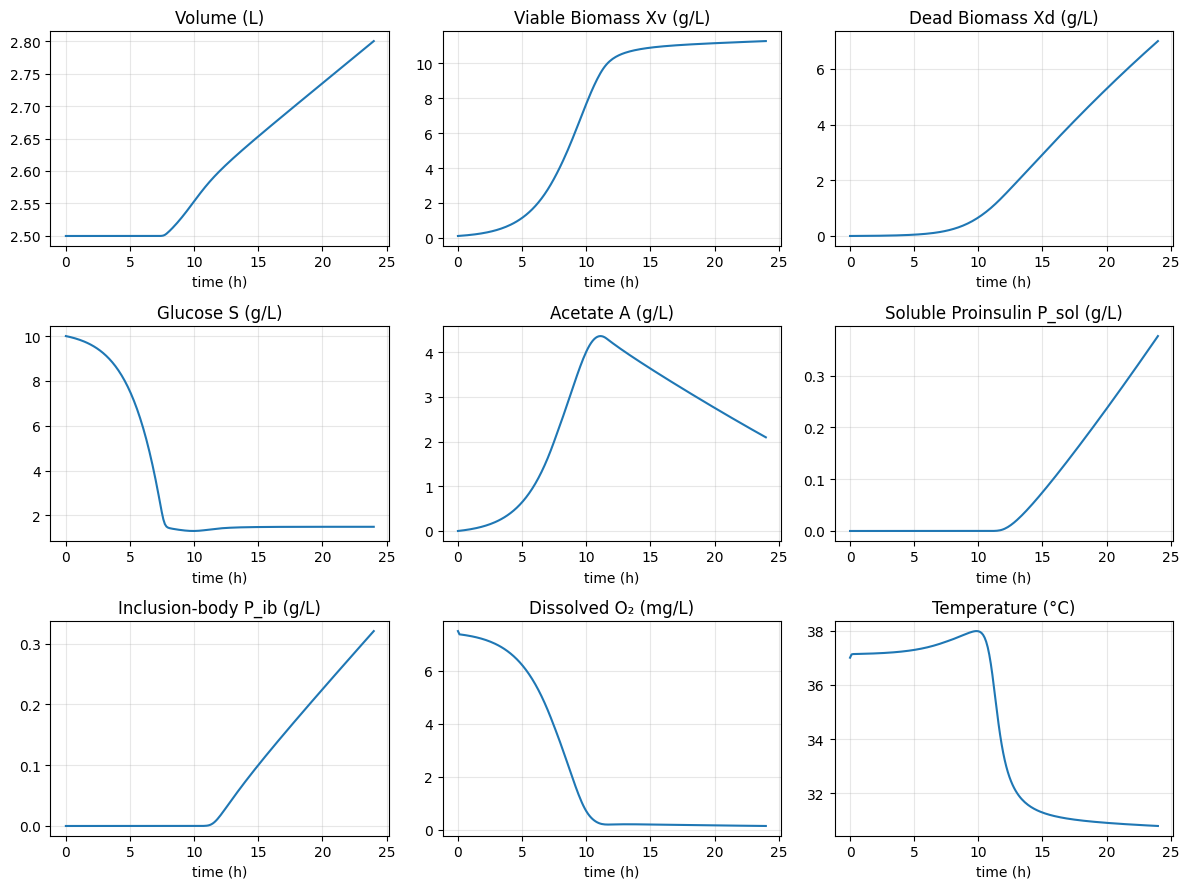

In [4]:
t, y, P_sol_final = run_simulation(T_set_prod=29.0, IPTG_dose=0.1, X_ind=10.0, F_s=0.1, S_f=500.0, N_rpm=800.0, F_air_vvm=1.5)
P_ib_final = y[6, -1]
print(f'baseline soluble titre: {P_sol_final:.3f} g/L')
print(f'baseline inclusion-body titre: {P_ib_final:.3f} g/L')
total = P_sol_final + P_ib_final
print(f'soluble fraction: {P_sol_final / (total + 1e-09):.1%}   total: {total:.3f} g/L')
labels = ['Volume (L)', 'Viable Biomass Xv (g/L)', 'Dead Biomass Xd (g/L)', 'Glucose S (g/L)', 'Acetate A (g/L)', 'Soluble Proinsulin P_sol (g/L)', 'Inclusion-body P_ib (g/L)', 'Dissolved O₂ (mg/L)', 'Temperature (°C)']
fig, ax = plt.subplots(3, 3, figsize=(12, 9))
for i, a in enumerate(ax.flat):
    a.plot(t, y[i])
    a.set_title(labels[i])
    a.set_xlabel('time (h)')
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()


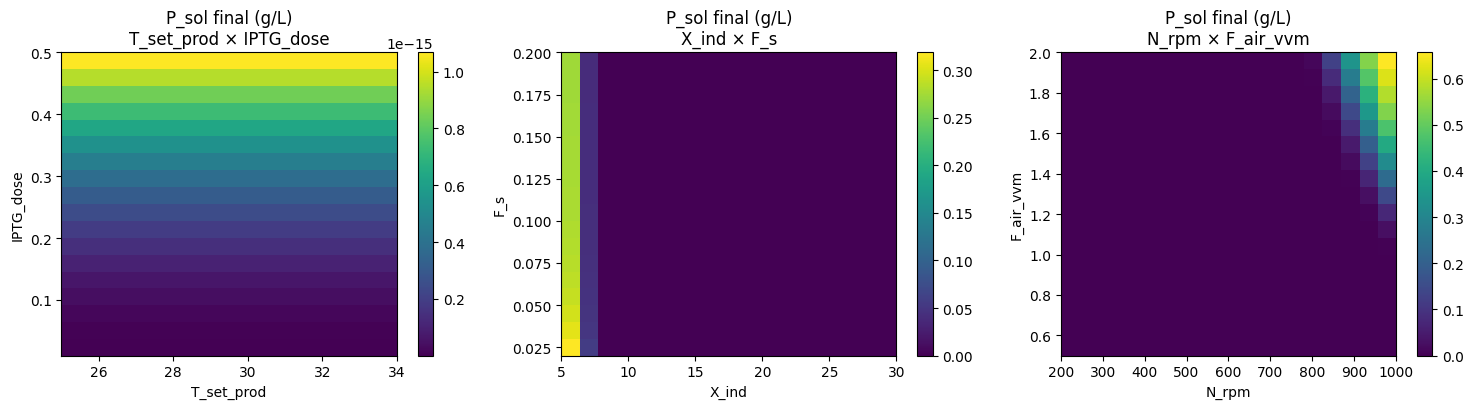

In [5]:
def parameter_sweep(x_param, x_values, y_param, y_values, base_params):
    Z = np.zeros((len(y_values), len(x_values)))
    for i, yv in enumerate(y_values):
        for j, xv in enumerate(x_values):
            args = dict(base_params)
            args[x_param] = xv
            args[y_param] = yv
            try:
                Z[i, j] = run_simulation(**args, num_evaluations=50)[2]
            except RuntimeError:
                Z[i, j] = np.nan
    return Z
base_params = dict(T_set_prod=29.0, IPTG_dose=0.1, X_ind=15.0, F_s=0.08, S_f=400.0, N_rpm=600.0, F_air_vvm=1.0)
sweep_pairs = [('T_set_prod', np.linspace(25, 34, 18), 'IPTG_dose', np.linspace(0.01, 0.5, 18)), ('X_ind', np.linspace(5, 30, 18), 'F_s', np.linspace(0.02, 0.2, 18)), ('N_rpm', np.linspace(200, 1000, 18), 'F_air_vvm', np.linspace(0.5, 2.0, 18))]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for k, (xn, xv, yn, yv) in enumerate(sweep_pairs):
    Z = parameter_sweep(xn, xv, yn, yv, base_params)
    im = ax[k].imshow(Z, origin='lower', aspect='auto', extent=[xv[0], xv[-1], yv[0], yv[-1]], cmap='viridis')
    ax[k].set_xlabel(xn)
    ax[k].set_ylabel(yn)
    ax[k].set_title(f'P_sol final (g/L)\n{xn} × {yn}')
    plt.colorbar(im, ax=ax[k])
plt.tight_layout()
plt.show()


optimum P_sol: 1.409 g/L
    T_set_prod = 25
     IPTG_dose = 0.3873
         X_ind = 14.09
           F_s = 0.03395
           S_f = 571.6
         N_rpm = 993.9
     F_air_vvm = 2
  P_ib at optimum: 0.723 g/L  (66% soluble)


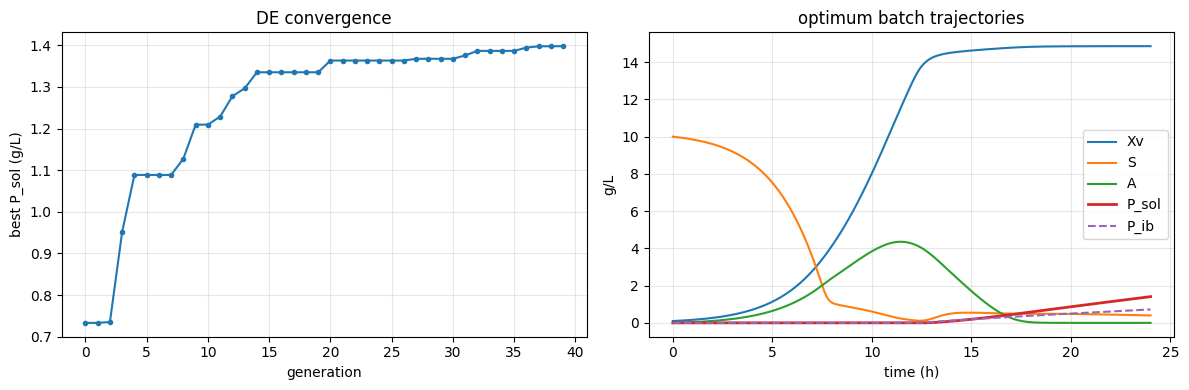

In [6]:
opt_bounds = [(25.0, 34.0), (0.01, 0.5), (5.0, 30.0), (0.02, 0.2), (200.0, 600.0), (200.0, 1000.0), (0.5, 2.0)]
opt_history = []

def neg_P_sol(x):
    try:
        return -run_simulation(*x, num_evaluations=50)[2]
    except RuntimeError:
        return 0.0

def cb(xk, convergence):
    opt_history.append(-neg_P_sol(xk))
    return False
opt = differential_evolution(neg_P_sol, opt_bounds, popsize=15, maxiter=40, tol=0.001, seed=0, polish=True, callback=cb, updating='deferred', workers=1)
names = ['T_set_prod', 'IPTG_dose', 'X_ind', 'F_s', 'S_f', 'N_rpm', 'F_air_vvm']
print(f'optimum P_sol: {-opt.fun:.3f} g/L')
for n, v in zip(names, opt.x):
    print(f'  {n:>12s} = {v:.4g}')
t_o, y_o, _ = run_simulation(*opt.x)
print(f'  P_ib at optimum: {y_o[6, -1]:.3f} g/L  ({y_o[5, -1] / (y_o[5, -1] + y_o[6, -1] + 1e-09):.0%} soluble)')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(opt_history, marker='o', ms=3)
ax[0].set_xlabel('generation')
ax[0].set_ylabel('best P_sol (g/L)')
ax[0].set_title('DE convergence')
ax[0].grid(alpha=0.3)
ax[1].plot(t_o, y_o[1], label='Xv')
ax[1].plot(t_o, y_o[3], label='S')
ax[1].plot(t_o, y_o[4], label='A')
ax[1].plot(t_o, y_o[5], label='P_sol', lw=2)
ax[1].plot(t_o, y_o[6], label='P_ib', ls='--')
ax[1].set_xlabel('time (h)')
ax[1].set_ylabel('g/L')
ax[1].legend()
ax[1].set_title('optimum batch trajectories')
ax[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()
